<a href="https://colab.research.google.com/github/AVONZED/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/end_to_end_openRF/End_to_end_OpenRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authors: Matthias Hornisch, Arne Christopher Freiherr von Zedlitz-Neukirch - Chair of High Frequency Electronics, RWTH Aachen University

# **Lowering the Barrier to RFIC Design: An End-to-End Open-Source Workflow Using Open PDKs**

A major challenge in today’s RFIC design landscape is the high barrier to entry. Commercial design tools are often prohibitively expensive, while access to state-of-the-art semiconductor technologies may be restricted. At the same time, openly available PDKs and EDA tools can present limitations in RF design capabilities, and integrating the diverse set of tools required for a complete RF workflow can be a significant undertaking in itself.

This submission aims to address these challenges by presenting a straightforward, end-to-end RFIC design workflow built entirely around open-source tools and the openly available 130 nm SiGe BiCMOS process design kit (PDK) from IHP. The workflow enables small-signal and large-signal circuit simulations, as well as electromagnetic (EM) simulations, within a unified Linux-based environment. With a strong emphasis on education and accessibility, our goal is to significantly lower the barrier to entry for RFIC design by providing a practical, reproducible workflow that can be adopted and extended by students, researchers, and the wider open-source hardware community.

The submission is structured into two main parts:



1.   **Introduction to the Open-Source RF Toolchain:** An overview of the software components, the IHP SG13G2 PDK, and their integration into a functional Linux-based design environment. This section highlights the key configuration and integration challenges addressed, along with the capabilities of the individual tools and their role in the overall workflow.
2.   **Demonstration of the End-to-End RF Design Workflow Using an Example Amplifier Circuit:** An illustrative amplifier design will demonstrate the workflow in practice, focusing on:
  *   **RF-specific simulation capabilities:** Demonstrating small-signal analysis, large-signal simulation using harmonic balance, and EM simulation.
  *   **Usability and workflow integration:** Showcasing how the different tools work together to provide a straightforward and accessible RF design experience.
  *   **Results visualization and analysis:** Presenting and interpreting simulation results using the integrated tools and supplementary Python scripts.


Through this combination of toolchain documentation and a practical RF design example, the submission aims to demonstrate that a capable, reproducible, and accessible RFIC design workflow can be established entirely with open-source software and an openly available semiconductor PDK.


\subsection{Introductory Remarks} Unlike other commercial IC design software, the correct installation and setup of the IHP-Open-PDK requires numerous manual steps and decisions by the user. Among other things this thesis should also serve as an installation and setup instruction for succeeding users of the PDK. Hence, a detailed first-hand experience will be provided in this Chapter, highlighting especially custom-made decisions and parts beyond the official documentation, aiming to present a reference point for future setup processes. Another motivation for redrawing the installation process in such detail is that the official installation instructions on IHP's official PDK documentation website \autocite{IHP_PDK_documentation_website} was found not to be very chronological in the current state.

The problem of simplifying this setup process has already been addressed in the past. Developed by the Institute for Integrated Circuits and Quantum Computing at the JKU Linz, a Docker/Podman container called IIC-OSIC-TOOLS containing the IHP-Open-PDK next to other open-source PDKs together with numerous design tools has been created \autocite{zotero-item-1359}. Principally, such an approach facilitates the installation process by just installing and deploying the container. While such a solution was not considered for this study due to operating system and performance concerns, but mainly because the projects README clarifies that the IHP-PDK is not fully supported yet, it might be worth it in the future, especially because the IIC-OSIC-TOOLS project is being updated quite actively these days.

The author wants to clarify that the IHP-Open-PDK has been installed and set up on two distinct machines with the first one running Ubuntu Linux 24.04.4, and the second one operating with Rocky Linux 9.8. The reason for this is that the official online documentation recommends the PDK to be installed on an Ubuntu Linux 24.04.4 machine. Thus, a private PC was set up and became the main PC to work with during this beginning of the thesis. Later, a dedicated PC with an x86-64 architecture was provided and set up with Rocky Linux 9.8, as this is the Linux flavour used at the \ac{HFE}, showing that an installation is also possible on such PCs at the institute. The installation processes on both systems differ quite significantly, and also, during the temporal gap between the two installations of a few months, different versions of the PDK and tools were installed. However, reporting the whole installation process for both systems would mean a lot of multiplication, which is why only the installation on the Rocky Linux PC is shown in detail. For proper documentation and reproducibility reasons, a list of most important software used on the Ubuntu Linux setup is attached at the end of this Chapter ???, while the software versions on the Rocky Linux is kept in the appendix ???. Moreover, a terminal command list is attached to this thesis in the appendix ???, aiming to mimic the complete installation instructions that were used to get the PDK installed on the Rocky Linux 9.8 PC. This list is a reconstruction based on terminal recordings and hopefully prevents succeeding users from all the conflicts the author ran into.

When doing all the installations, the question arose on where to put all the software on the system. The decision was made towards the destination that is used by most tools as the default, naming the \texttt{/usr/local}. This directory is available system-wide for all users, and is typically used for software that is custom-build. Exceptions are made for OpenVAF and openEMS, which are installed as self-contained software in \texttt{/opt} and \texttt{\char~{}/opt}, respectively. By doing so, official installation guidelines were followed, but openEMS is therefore only available for the current account. Before installing the programs into their destinations, they were downloaded into a folder \texttt{\char~{}/packages} to keep them all at one place. A system-wide install as conducted here naturally means that root access is required for the machine.

The structure of the upcoming Chapter is as follows: First, the installation of the external tools is redrawn, also covering the installation of necessary dependencies. Second, the installation of the IHP-Open-PDK itself is presented. The replay of this installation procedure is not exactly matching the conducted process for the reason of a better structured Chapter, but it is also chosen to be executable in the presented order from top to bottom. After the pure installation part, we will proceed with the setup process for both the PDK and the external tools, targeting a read-to-use state of these. Finally, some remarks and hints are given on how the PDK and the tools could be updated in the future.

\noindent
\textbf{Basic tools and dependencies} \quad
Many tools that will be installed later require a build from source, which is why we make sure to have the necessary tools for the build toolchain on the system, including the GNU \texttt{gcc} code compiler and the \texttt{make} tool. Such build tools and most of the other packages listed in the documentation \autocite{IHP_open_pdk_dependencies} were installed. A list aiming to reconstruct a complete install of these build and development tools and dependencies is shown in the appendix \ref{app:rocky-installation-commands}.

In [ ]:
# Extra repositories
sudo dnf install -y epel-release
sudo dnf config-manager --set-enabled crb

# Refresh repository metadata
sudo dnf makecache

# Autoconf
sudo dnf install -y autoconf271
printf '\n# autoconf\nsource /opt/rh/autoconf271/enable\n' >> ~/.bashrc
source ~/.bashrc

# Basic build tools and compilers
sudo dnf install -y \
    gcc \
    gcc-c++ \
    gcc-gfortran \
    clang \
    make \
    cmake \
    binutils \
    gdb \
    glibc-devel \
    libtool \
    automake \
    bison \
    libtool \
    gperf \
    swig \
    flex

# Version control, patching and debugging
sudo dnf install -y \
    git \
    patchutils \
    diffstat \
    strace \
    ltrace \
    valgrind \
    valgrind-devel \
    systemtap

# Build and documentation tools
sudo dnf install -y \
    asciidoc \
    source-highlight \
    help2man \
    groff \
    perl \
    perl-podlators

# Fedora/RPM development tools
sudo dnf install -y \
    jna \
    intltool \
    perl-Fedora-VSP \
    perl-generators \
    pesign

# Qt development - especially for Qucs-S and KLayout
sudo dnf install -y \
    qt5-qtbase-devel \
    qt5-qtxmlpatterns \
    qt5-qtxmlpatterns-devel \
    qt5-qtmultimedia \
    qt5-qtmultimedia-devel \
    qt5-qtsvg \
    qt5-qtsvg-devel \
    qt5-qtbase-gui \
    qt5-qttools \
    qt5-qttools-devel


# Python development
sudo dnf install -y \
    python3 \
    python3-devel \
    python3.12 \
    python3.12-devel \
    python3-pip \
    python3-virtualenv \
    python3-sphinx \
    python3-tkinter \
    python3-pytest \
    python3-setuptools \
    python3-setuptools_scm \
    python3-Cython \
    python3-numpy \
    python3-h5py \
    python3-matplotlib

# Tcl/Tk
sudo dnf install -y \
    tcl \
    tcl-devel \
    tk \
    tk-devel

# X11, GUI and graphics libraries
sudo dnf install -y \
    libXpm \
    libXpm-devel \
    gtk3-devel \
    libX11 \
    libX11-devel \
    libX11-xcb \
    libXrender \
    libXrender-devel \
    libxcb \
    libXaw-devel \
    cairo \
    cairo-devel \
    libjpeg-turbo-devel \
    libffi-devel \
    libharu-devel

# Compression, parsing and general libraries
sudo dnf install -y \
    zlib \
    zlib-devel \
    readline-devel \
    gettext

# Boost and C++ libraries
sudo dnf install -y \
    boost-system \
    boost-devel \
    boost-python3-devel \
    boost-filesystem \
    spdlog-devel \
    eigen3-devel

# Numerical and scientific libraries
sudo dnf install -y \
    fftw \
    fftw-devel \
    suitesparse \
    suitesparse-devel \
    gperftools-devel

# XML and Git libraries
sudo dnf install -y \
    libgit2 \
    libgit2-devel \
    libxml2 \
    perl-XML-LibXML

# Image and plotting support
sudo dnf install -y \
    perl-GD

# Graphs, visualization and utilities
sudo dnf install -y \
    graphviz \
    tree \
    btop \
    xterm

# Numerical computing, e.g. for openEMS
sudo dnf install -y \
    octave \
    octave-devel

# Ruby development
sudo dnf install -y \
    ruby \
    ruby-devel

# Miscellaneous utilities
sudo dnf install -y \
    curl \
    time

# Not provided by a dnf repository
sudo python3 -m pip install pandas
sudo python3 -m pip install xdot

\noindent
\textbf{LEMON} \quad
The \texttt{liblemon} package, which is a library providing algorithms for combinatorial optimization tasks \autocite{LEMON_main_webpage}, has to the best of the authors knowledge no equivalent on any repository managed by \texttt{dnf}. Thus, the package was built and installed from source as shown in List.~\ref{lst:LEMON-install}, guided by the official installation documentation \autocite{LEMON_installation_guide}.

In [ ]:
# LEMON
cd
mkdir packages
cd packages
wget http://lemon.cs.elte.hu/pub/sources/lemon-1.0.tar.gz
tar xvzf lemon-1.0.tar.gz
cd lemon-1.0
./configure
make -j$(nproc)
sudo make install

\subsection{External Tool Installation}
\label{section:External_tool_installation}
We first cover the installation of the external tools because the setup of the PDK partly requires the tools to be set up.


\subsubsection{OpenVAF}
\label{section:OpenVAF_installation}
OpenVAF is a Verilog-A compiler. This piece of software is needed because the IHP-Open-PDK provides several Verilog-A device models that we have to compile our own. From the official OpenVAF download website \autocite{OpenVAF_download}, the latest executable was downloaded and installed using the set of instructions in List.~\ref{lst:OpenVAF-install}.

In [ ]:
# openvaf
cd ~/packages
wget https://openva.fra1.cdn.digitaloceanspaces.com/\
openvaf_23_5_0_linux_amd64.tar.gz
sudo mkdir -p /opt/openvaf
tar xvzf openvaf_23_5_0_linux_amd64.tar.gz -C /opt/openvaf
printf '\n# OpenVAF\nexport PATH="/opt/openvaf:$PATH"\n' >> ~/.bashrc
source ~/.bashrc

\subsubsection{ngspice}
\label{section:ngspice_installation}
ngspice is an open-source \ac{SPICE} \autocite{ngspice_web}, hosted on SourceForge \autocite{ngspice_source}. During the installation process, incompatibilities occurred due to an outdated \texttt{autoconf} version, as already mentioned in Section~\ref{section:Build_tools_and_dependencies}. With the instructions for \texttt{autoconf} from above, the List.~\ref{lst:ngspice-install} should install ngspice to the system, following IHP's documentation closely \autocite{IHP_ngspice_instruction}. The author wants to highlight that it is especially important not to execute the \texttt{autogen.sh} file with a preceding \texttt{sudo}, because this will likely invoke another system install from \texttt{autoconf} whose version is probably $<2.70$.

In [ ]:
# ngspice
cd ~/packages
git clone https://git.code.sf.net/p/ngspice/ngspice ngspice-ngspice
cd ngspice-ngspice
./autogen.sh
./configure --enable-osdi
make -j$(nproc)
sudo make install
cd ..
rm -rf ngspice-ngspice

\subsubsection{ADMS}
\label{section:ADMS_installation}
As the OpenVAF compiler compiles Verilog-A models for ngspice schematic-level simulations, so does the \ac{ADMS} tool for device models that will be used in Xyce simulations. The software is hosted on GitHub and since the installation instructions are currently designed to target Debian Linux distributions only, a complete terminal snipped is provided in List.~\ref{lst:AMDS-install} for the Rocky Linux install. As stated by IHP in the later Xyce installation instructions, we should use a cmake-based build.

In [ ]:
# ADMS
cd ~/packages
wget https://github.com/Qucs/ADMS/releases/\
download/release-2.3.7/adms-2.3.7.tar.gz
tar xvfz adms-2.3.7.tar.gz
cd adms-2.3.7
mkdir build
cd build
cmake .. -DCMAKE_INSTALL_PREFIX=/usr/local
sudo make install

\subsubsection{Xyce}
\label{section:Xyce_installation}
Xyce is a SPICE-compatible circuit simulator developed as an open-source tool by Sandia National Laboratories \autocite{About_Xyce, XyceParallelElectronic2013}. In contrast to the current ngspice, Xyce is capable of \ac{HB} simulations and therefore enabling such large-signal schematic-level simulations which are essential for analog RFIC designs. Moreover, Xyce offers the option to be built and run in parallel, making it attractive for expensive simulations with e.g. large sweep setups. Despite that a serial build was chosen for simplicity. The installation is reported to be demanding and error-prone due to multiple versioning and dependency issues \autocite{IHP_Xyce_install_instructions, Xyce_building_guide}, which is why the proposed procedure should be followed closely if not already specified otherwise by IHP. The reader is pointed to the fact that in the conducted installation on the Rocky Linux PC, the paths Xyce and Trilinos were downloaded into were redirected from the home directory to \texttt{\char`~{}/packages}.

In [ ]:
# XYCE
sudo dnf install -y \
    blas \
    blas-devel \
    lapack \
    lapack-devel \

cd ~/packages
git clone https://github.com/trilinos/Trilinos.git Trilinos
cd Trilinos
git checkout trilinos-release-12-12-1
cd ..
mkdir trilinos_build
cd trilinos_build
touch reconfigure.sh
chmod +x reconfigure.sh

cat > reconfigure.sh << 'EOF'
#!/bin/sh
SRCDIR="$HOME/packages/Trilinos/"
ARCHDIR="/usr/local"
FLAGS="-O3 -fPIC"
cmake \
-DCMAKE_C_COMPILER=gcc \
-DCMAKE_CXX_COMPILER=g++ \
-DCMAKE_Fortran_COMPILER=gfortran \
-DCMAKE_CXX_FLAGS="$FLAGS" \
-DCMAKE_C_FLAGS="$FLAGS" \
-DCMAKE_Fortran_FLAGS="$FLAGS" \
-DCMAKE_INSTALL_PREFIX=$ARCHDIR \
-DCMAKE_MAKE_PROGRAM="make" \
-DTrilinos_ENABLE_NOX=ON \
  -DNOX_ENABLE_LOCA=ON \
-DTrilinos_ENABLE_EpetraExt=ON \
  -DEpetraExt_BUILD_BTF=ON \
  -DEpetraExt_BUILD_EXPERIMENTAL=ON \
  -DEpetraExt_BUILD_GRAPH_REORDERINGS=ON \
-DTrilinos_ENABLE_TrilinosCouplings=ON \
-DTrilinos_ENABLE_Ifpack=ON \
-DTrilinos_ENABLE_AztecOO=ON \
-DTrilinos_ENABLE_Belos=ON \
-DTrilinos_ENABLE_Teuchos=ON \
-DTrilinos_ENABLE_COMPLEX_DOUBLE=ON \
-DTrilinos_ENABLE_Amesos=ON \
  -DAmesos_ENABLE_KLU=ON \
-DTrilinos_ENABLE_Amesos2=ON \
 -DAmesos2_ENABLE_KLU2=ON \
 -DAmesos2_ENABLE_Basker=ON \
-DTrilinos_ENABLE_Sacado=ON \
-DTrilinos_ENABLE_Stokhos=ON \
-DTrilinos_ENABLE_Kokkos=ON \
-DTrilinos_ENABLE_ALL_OPTIONAL_PACKAGES=OFF \
-DTrilinos_ENABLE_CXX11=ON \
-DTPL_ENABLE_AMD=ON \
-DAMD_LIBRARY_DIRS="/usr/lib" \
-DTPL_AMD_INCLUDE_DIRS="/usr/include/suitesparse" \
-DTPL_ENABLE_BLAS=ON \
-DTPL_ENABLE_LAPACK=ON \
$SRCDIR
EOF

./reconfigure.sh
make -j$(nproc)
sudo make install

cd ~/packages
git clone https://github.com/Xyce/Xyce.git
cd Xyce
git checkout Release-7.8.0
./bootstrap
cd ..
mkdir xyce_build
cd xyce_build
touch reconfigure.sh
chmod +x reconfigure.sh

cat > reconfigure.sh << 'EOF'
#!/bin/sh
$HOME/packages/Xyce/configure \
CXXFLAGS="-O3 -fPIC" \
ARCHDIR="/usr/local" \
CPPFLAGS="-I/usr/include/suitesparse" \
--enable-stokhos \
--enable-amesos2 \
--enable-user-plugin \
--enable-admsmodels \
--enable-shared \
--enable-xyce-shareable
EOF

./reconfigure.sh
make -j$(nproc)
sudo make install

\subsubsection{Qucs-S}
\label{section:Qucs-S_installation}
Qucs stands for \textit{Quite universal circuit simulator}. Qucs-S is a fork of the original Qucs project \autocite{Qucs_web} which pursues to combine the simplicity of the Qucs \ac{GUI} with SPICE simulation backends \autocite{qucs_s_io}. The capability to run a drawn schematic with a simulator like Xyce makes it an appropriate tool for the simulation of RF circuits. IHP itself branched the Qucs-S project and made adjustments to the source code such that the desired PDK-related functionalities like custom schematic symbols are available from within Qucs-S. By now the IHP-branch is named \texttt{dev/xml\_devices}. The fact that IHP hosts its own branch means that we have to compile and build Qucs-S from source and can't simply install precompiled binaries.

Installation instructions which can be found on the official Qucs-S GitHub page \autocite{Qucs_S_xmldevices_git} form the basis for this installation manual. However, the proposed dependency instructions for Fedora Linux on this page were found not to be appropriate for this Rocky Linux install due to naming conflicts, which is why the installation log of the dependencies in the appendix \ref{app:rocky-installation-commands} should serve as a much better reference. For the installation of packages needed for the creating of xml-based devices IHP integrates into Qucs-S, a README.md has been found and is referenced here although not followed explicitly due to post-installation discovery \autocite{qucs_s_xml}. Naturally, all these dependencies should be installed ahead of the main Qucs-S install. A special remark is given here regarding the versioning. Even though the \texttt{versions.txt} in the root of the IHP-Open-PDK project specifies \textit{qucs-s s25.2.0}, this exact release label must not be checked out directly with \texttt{git checkout 25.2.0}. It would set the git HEAD away from the IHP-specific branch and thus install the wrong version.

In [ ]:
# Qucs-S
sudo dnf install -y \
    dos2unix \
    xsd \
    qt6-qtbase-devel \
    qt6-qtsvg-devel \
    qt6-qttools-devel \
    qt6-qtcharts-devel

cd ~/packages
git clone https://github.com/beltoforion/muparser.git
cd muparser/
sudo cmake -S . -B build \
    -DCMAKE_BUILD_TYPE=Release \
    -DCMAKE_INSTALL_PREFIX=/usr/local
sudo cmake --build build -j"$(nproc)"
sudo cmake --install build
echo '/usr/local/lib64' | sudo tee /etc/ld.so.conf.d/muparser.conf
sudo ldconfig

# One might not need manual install of libxerces-c and libxerces-c-devel
# since dnf should have taken care of these xsd dependencies
# when 'sudo dnf install xsd' from further above.
wget https://codesynthesis.com/download/xsd/4.2/\
rhel/rhel9.2/x86_64/libxerces-c-3.2.4-3.el9.x86_64.rpm
sudo dnf install libxerces-c-3.2.4-3.el9.x86_64.rpm

wget https://codesynthesis.com/download/xsd/4.2/\
rhel/rhel9.2/x86_64/libxerces-c-devel-3.2.4-3.el9.x86_64.rpm
sudo dnf install libxerces-c-devel-3.2.4-3.el9.x86_64.rpm

git clone --recurse-submodules --branch dev/xml_devices https://github.com/ra3xdh/qucs_s.git
git submodule init
git submodule update
mkdir builddir
cd builddir
cmake ..  -DCMAKE_INSTALL_PREFIX=/usr/local
make -j$(nproc)
sudo make install

\subsubsection{KLayout}
\label{section:KLayout_installation}
The layout tool that will be utilized in this study is KLayout \autocite{KLayout_web}. Currently, the latest build of KLayout for Rocky Linux 9 on the official KLayout download website \autocite{klayout_download} conflicts with the IHP-Open-PDK, because it was build against Python 3.9, where the PDK includes code that requires Python 3.10 or newer. Luckily, the website contains the raw sources and build instructions for CentOS Linux, which is also based on RHEL. The specified dependencies are already covered by the dependencies section in the appendix Rocky Linux install log \ref{app:rocky-installation-commands}, which is why we only need to execute the commands as follows. For new installs, on should have a look at the \texttt{versions.txt} in the IHP-Open-PDK root directory \autocite{IHP_github} to choose the KLayout version that has been tested with the PDK. In September 2026 it is version \texttt{0.30.5}. However, for this installation the newest available version \texttt{0.30.12} has been installed as presented in List.~\ref{lst:KLayout-install}.

\noindent
Additionally, the generated KLayout executable is set to \texttt{PATH} to be found by the shell, shown in List.~\ref{lst:KLayout-PATH}.

In [ ]:
# KLayout
cd ~/packages
wget https://www.klayout.org/downloads/source/klayout-0.30.12.tar.gz
tar hzxvf klayout-0.30.12.tar.gz
cd klayout-0.30.12
./build.sh

cat >> ~/.bashrc << 'EOF'

# KLayout executable
export PATH="$HOME/packages/klayout-0.30.12/build-release:$PATH"
export LD_LIBRARY_PATH="$HOME/packages/klayout-0.30.12/build-release:"\
"$LD_LIBRARY_PATH"
EOF

\subsubsection{openEMS}
\label{section:openEMS_installation}
In this work, an open-source electromagnetic field solver called openEMS \autocite{openEMS_citation_reference} is used for EM simulations. The openEMS project actually incorporates additional software for handling geometry and pre-simulation preview next to the pure simulation kernel. Apart from the main project, some dependencies have to be installed to. The installation process of these is documented well \autocite{openEMS_clone_build_install} and did not cause any issues. Used commands for getting the dependencies installed on the Rocky Linux PC are kept in the appendix \ref{app:rocky-installation-commands}.

In [ ]:
# openEMS
sudo dnf install -y \
    tinyxml-devel \
    vtk-devel \
    hdf5-devel \
    CGAL-devel \
    vtk-qt \
    paraview \
    gengetopt \
    perl-pod2pdf

cd ~/packages
git clone --recursive https://github.com/thliebig/openEMS-Project.git
cd openEMS-Project/
./update_openEMS.sh ~/opt/openEMS --python

cat >> ~/.bashrc << 'EOF'

# openEMS executable
export PATH="$HOME/opt/openEMS/bin:$PATH"
EOF

\subsection{PDK Installation Process}
\label{section:PDK_installation_process}
With all the dependencies and tools installed, we are finally ready to install the IHP-Open-PDK itself. IHP hosts its IHP-Open-PDK on GitHub \autocite{IHP_github}. The project includes some git submodules, which is why we clone the repository using the option \texttt{\char`-{}-recurse-submodules} to clone these submodules as well. The installation was conducted as proposed from IHP \autocite{IHP_installation_web}, choosing to install the PDK in a directory named \textit{IHP\_PDK}.

\noindent
After that, it is essential to export some environmental variables such that e.g. KLayout and ngspice can interface the PDK cleanly. The instructions from IHP were modified a bit to hold the actual installation path and to correct for some syntax issues, as shown below in List.~\ref{lst:IHP-Open-PDK-bashrc}.

In [ ]:
# IHP-Open-PDK
mkdir ~/IHP_PDK
cd ~/IHP_PDK
git clone --branch dev --recurse-submodules \
https://github.com/IHP-GmbH/IHP-Open-PDK.git

cat >> ~/.bashrc << 'EOF'

# IHP-Open-PDK environmental variables
export PDK_ROOT=$HOME/IHP_PDK/IHP-Open-PDK
export PDK=ihp-sg13g2
export KLAYOUT_PATH="$HOME/.klayout:$PDK_ROOT/$PDK/libs.tech/klayout"
export KLAYOUT_HOME=$HOME/.klayout
EOF
source ~/.bashrc

\noindent
The PDK is hosting its Verilog-A models under \texttt{ihp-sg13g2/libs.tech/\allowbreak verilog-a}, but they are not compiled yet. With the previously installed OpenVAF and ADMS Verilog-A compilers, we now can do so. By executing these scripts below, \ac{OSDI} binaries for use with ngspice are being put into \texttt{libs.tech/\allowbreak ngspice/osdi}, where the ADMS script puts the models as .so shared objects into \texttt{libs.tech/xyce/plugis}. This will be important in the next Chapter when we set up simulations with Qucs-S.

In [ ]:
# Verilog-A models compilation
cd ~/IHP_PDK/IHP-Open-PDK/libs.tech/verilog-a
source openvaf-compile-va.sh
source adms-compile-va.sh

\subsubsection{PDK Python Environment}
\label{section:PDK_Python_environment}
Tools like KLayout require some Python packages to function properly. For this reason, IHP includes a \texttt{requirements.txt} in the root directory of the IHP-Open-PDK repository. Among other packages a \texttt{klayout} package is present in this file. The Python \texttt{klayout} package is needed for the KLayout \ac{API} to function properly, which is used by IHP to implement DRC and LVS functions. However, in our case we need to adjust this package name a bit since it would install a \texttt{klayout} package version \texttt{0.30.5}, but to match it with the actual KLayout version that was previously installed, the below command was executed. It really is just a copy of that \texttt{requirements.txt} with the \texttt{klayout} version adjusted. Also, it is mandatory to use \texttt{python3.12} here due to the same reason described in Section~\ref{section:KLayout_installation}. Additionally to the requirements from IHP, the List.~\ref{lst:pdkenv-install} will install the package \texttt{snp2le} \autocite{2026_snp2le}, which will be used for S-parameter to lumped element conversion later.

In [ ]:
# PDK Python environment
python3.12 -m venv ~/IHP_PDK/venv

cat >> ~/.bashrc << 'EOF'

# PDK environment alias
alias pdkenv='source ~/IHP_PDK/venv/bin/activate'
EOF
source ~/.bashrc

pdkenv
python -m pip install --upgrade pip
pip install flake8 \
    docopt \
    pandas \
    klayout=0.30.12 \
    pyyaml \
    gdstk \
    tqdm \
    termcolor
pip install snp2le
deactivate

\subsubsection{EM Simulation Interface}
\label{section:gds2openEMS}
openEMS is being interfaced with the help of an interface software called gds2openEMS. This Python package is responsible to create a simulation-ready model based on the design file and the actual call of the openEMS solver. At the moment of writing this thesis in October 2026, gds2openEMS is hosted on two different platforms, and we need the software from both platforms for the workflow described here. One gds2openEMS package is hosted on PyPI \autocite{gds2openEMS_pypi}, and the other one is available on GitHub \autocite{openems_ihp_sg13g2}. The latter one is actually a git submodule of the IHP-Open-PDK itself, so theoretically, we do not need to clone it again. However, it has been found that this PDK-included version of gds2openEMS is too outdated for the functions and features that are being used in this study. A clarifying hint at this point regarding the gds2openEMS PyPI package is that we do not create a Python virtual environment our own, since the openEMS installation with the option \texttt{\char`-{}-python} already constructed one in \texttt{\char`~{}/opt/openEMS}. In fact, one \textit{has to} use this exact Python environment, because it contains packages that gds2openEMS depends on and that are not available otherwise. List.~\ref{lst:gds2openEMS-install} renders how the gds2openEMS installation was achieved.

In [ ]:
# gds2openEMS from PyPI
cat >> ~/.bashrc << 'EOF'

# openEMS environment alias
alias openemsenv='source ~/opt/openEMS/venv/bin/activate'
EOF
source ~/.bashrc

openemsenv
python -m pip install --upgrade pip
pip install gds2openEMS
pip install -r ~/IHP_PDK/IHP-Open-PDK/requirements.txt
deactivate

# gds2openEMS from GitHub
cd ~/IHP_PDK
git clone https://github.com/VolkerMuehlhaus/gds2openEMS.git

\subsubsection{PDK Installation Scripts}
\label{section:PDK_installation_scripts}
To finish the pure installation tasks that are essential for the RF-workflow, some installation scripts have to be executed. The \texttt{install.py} script in \texttt{ihp-sg13g2/\allowbreak libs.tech/\allowbreak ngspice} creates a symlink to the \texttt{.spiceinit} file into the home directory. By executing the \texttt{install.py} script in \texttt{ihp-sg13g2/\allowbreak libs.tech/\allowbreak qucs-s} as in List.~\ref{lst:PDK-install-scripts}, the Qucs-S library files are copied to a \texttt{QucsWorkspace} folder in the home directory.

In [ ]:
# PDK symlink creation
pdkenv
python ~/IHP_PDK/IHP-Open-PDK/libs.tech/ngspice/install.py
python ~/IHP_PDK/IHP-Open-PDK/libs.tech/qucs-s/install.py

\subsection{Post-Installation Tool Setup}
\label{section:Post_installation_setup}
The previous Section covered all steps necessary to get the required software for the RF-workflow within the IHP-Open-PDK installed on a Rocky Linux PC. Before the actual workflow is described in the next Chapter, some tools require some basic setup. This Section here aims to get those tools set up such that they are ready-to-use, without going into details. A more in-depth explanation of the individual tools and their operating modes will be provided in the upcoming Chapter alongside the workflow description.


\subsubsection{Qucs-S}
\label{section:Post_installation_setup_Qucs_S}
Qucs-S should now be able to be started from within a terminal by typing \texttt{qucs-s}. First, one has to make sure that Qucs-S knows the path to the \texttt{QucsWorkspace} folder. Starting from the menu bar we navigate to \texttt{File} $\rightarrow$ \texttt{Application Settings} \allowbreak $\rightarrow$ \allowbreak \texttt{Locations}. Here, the \texttt{Qucs Home} text field should point to the \texttt{QucsWorkspace} folder in the home directory, which we can select using the Browse button to the right of that text field.

Additionally, we have to ensure that Qucs-S knows where to find the simulator executables from ngspice and Xyce. Again starting from the menu bar we navigate to \texttt{Simulation} \allowbreak $\rightarrow$ \allowbreak \texttt{Simulators Settings}. Here the text field \texttt{Ngspice \allowbreak executable \allowbreak location} was set to \texttt{usr/local/bin/ngspice}, where the field \texttt{Xyce \allowbreak executable \allowbreak location} holds \texttt{usr/local/bin/Xyce}. After that, Qucs-S should be set up correctly to get started with.


\subsubsection{KLayout}
\label{section:Post_installation_setup_KLayout}
KLayout requires some setup as well. By default, KLayout starts into a view-only mode, prohibiting changes to design files. To prevent that, we have to tell KLayout to always start in editable mode. By doing so, KLayout has to be started from a new terminal by typing \texttt{klayout}. KLayout should start its GUI, and by navigating to \texttt{File} \allowbreak $\rightarrow$ \allowbreak \texttt{Setup} \allowbreak $\rightarrow$ \allowbreak \texttt{Application} \allowbreak $\rightarrow$ \allowbreak \texttt{Editing Mode}, the tick box \texttt{Use editing model by default} can be ticked. After confirming and closing the program, KLayout should start into editable mode from now on.

KLayout coming from a fresh install does not offer helpful keyboard shortcuts. IHP addresses this issue and provides a list of shortcuts on their KLayout web page \autocite{IHP_KLayout_web}. These shortcuts are made accessible by copy-pasting them into the respective section inside the \texttt{klayoutrc} file, which is located in the \texttt{.klayout} folder in the home directory. Also, the default grid definitions should be set accordingly. Hereby it is important to first close KLayout itself before modifying the \texttt{klayoutrc} file, because otherwise KLayout overwrites any changes to that file at the next program startup.

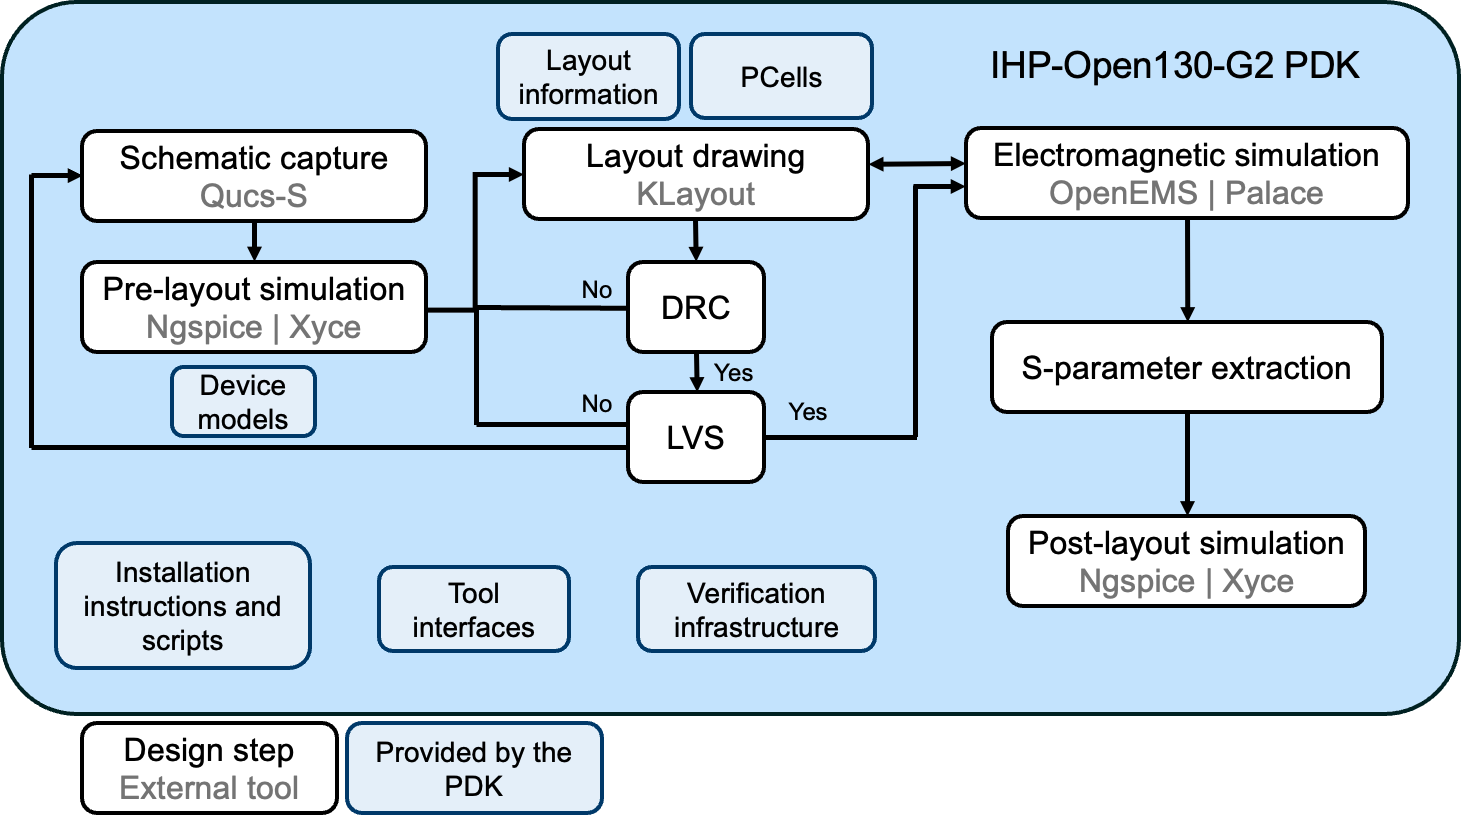

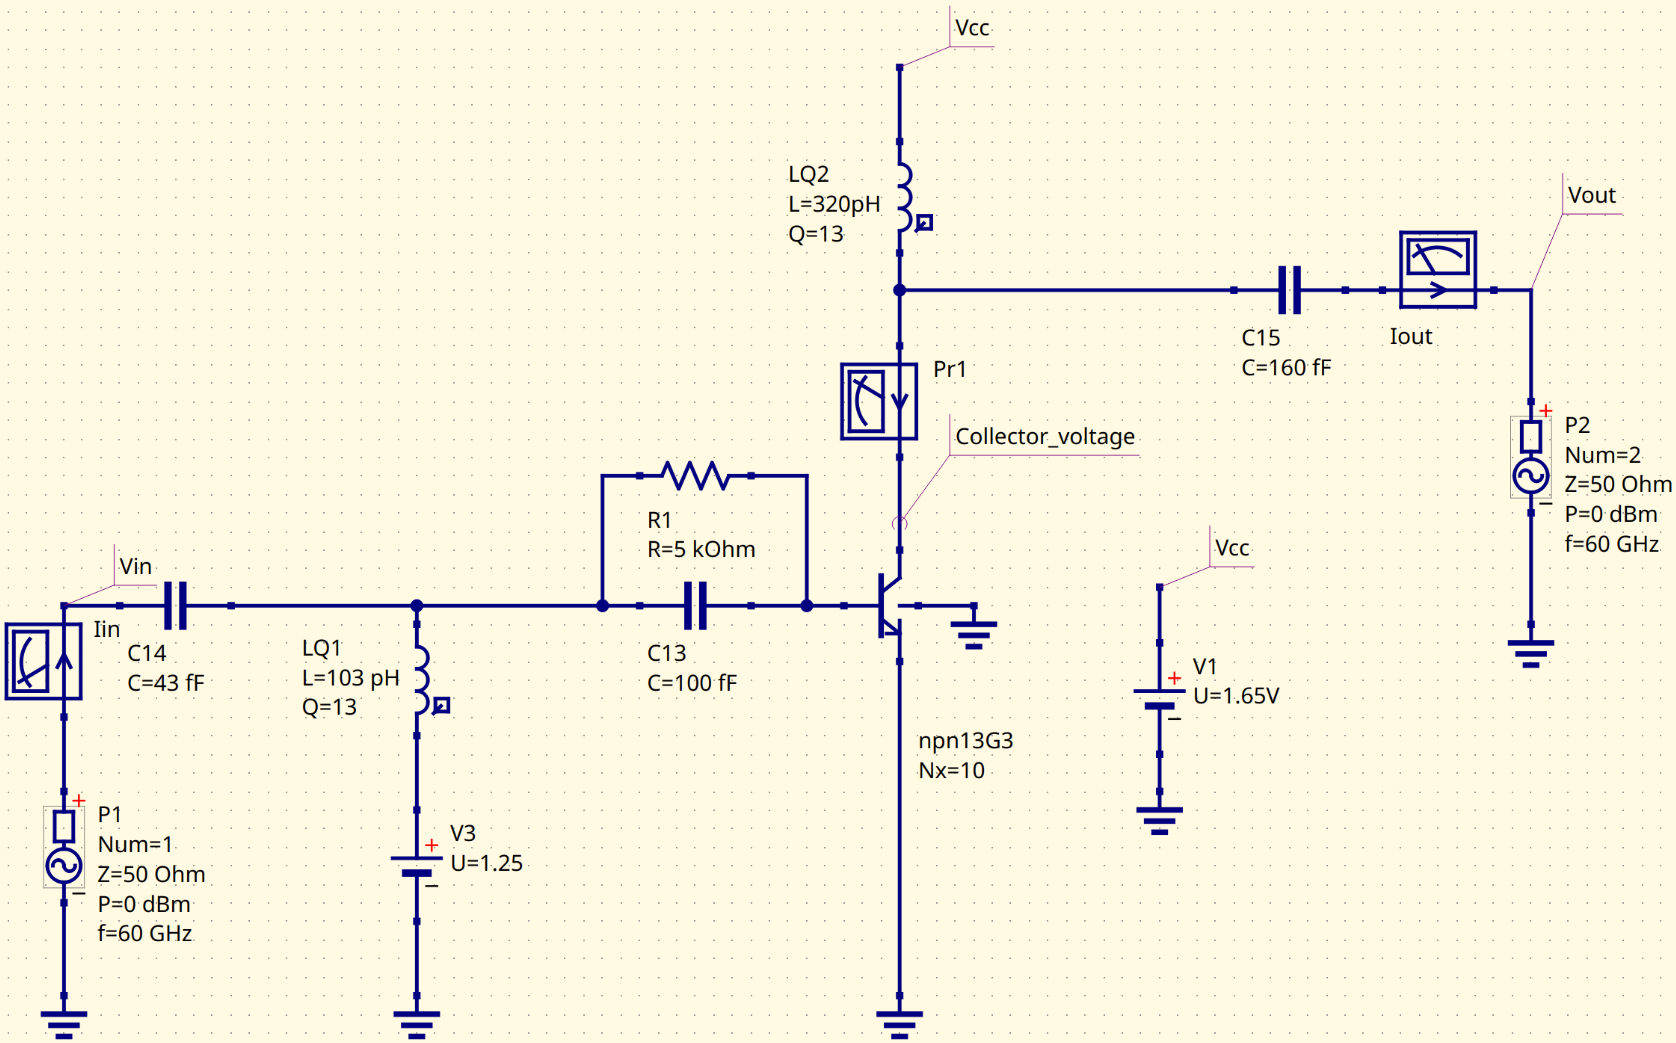

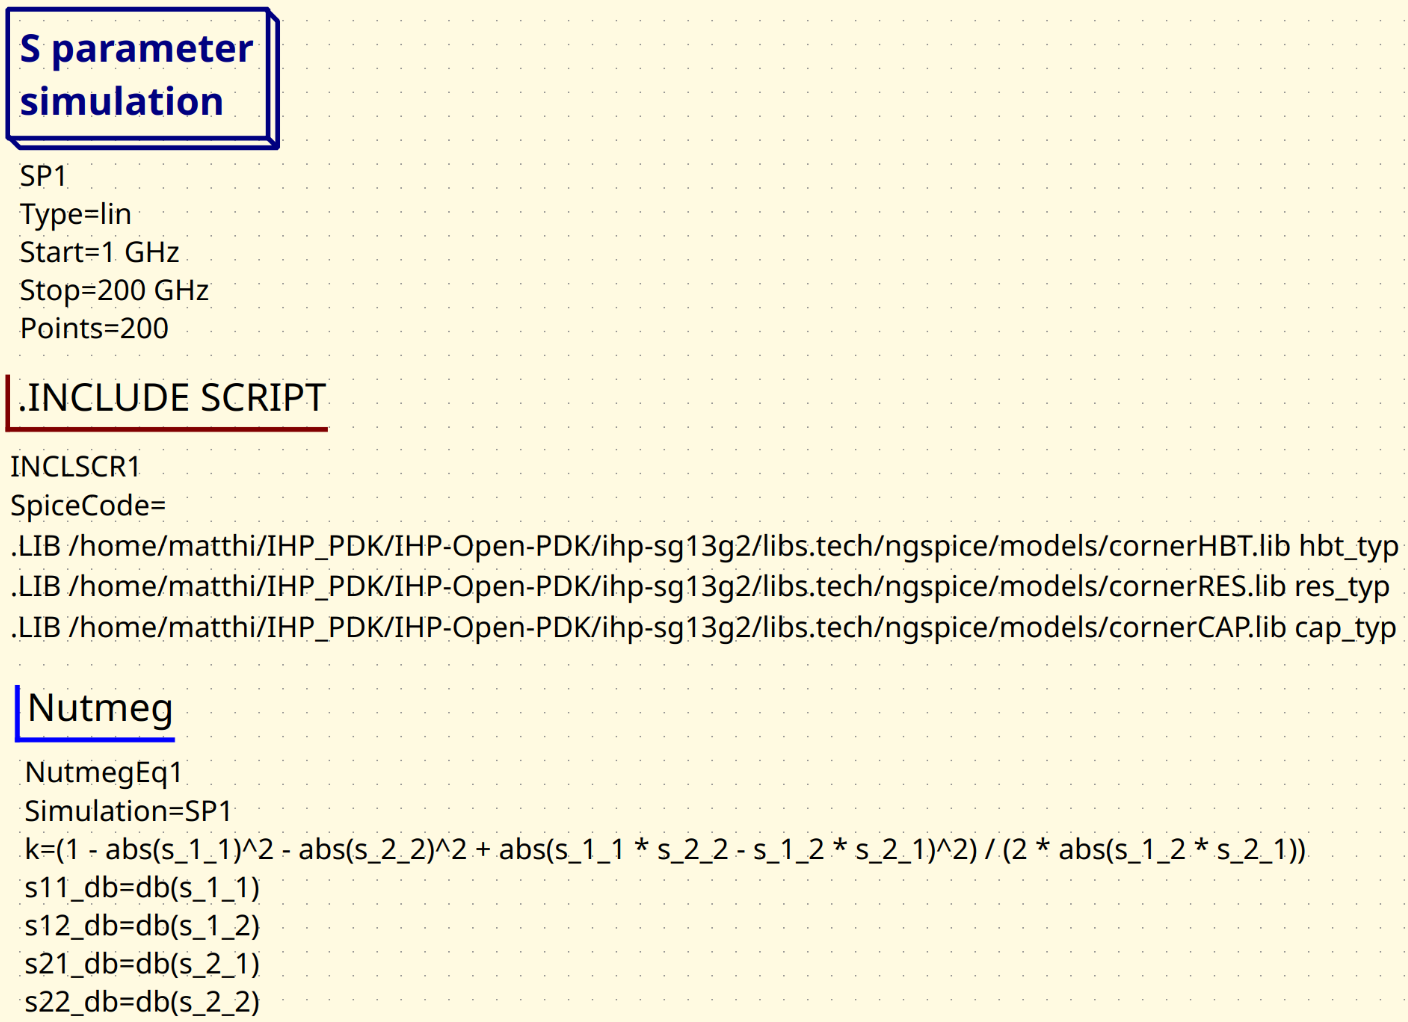

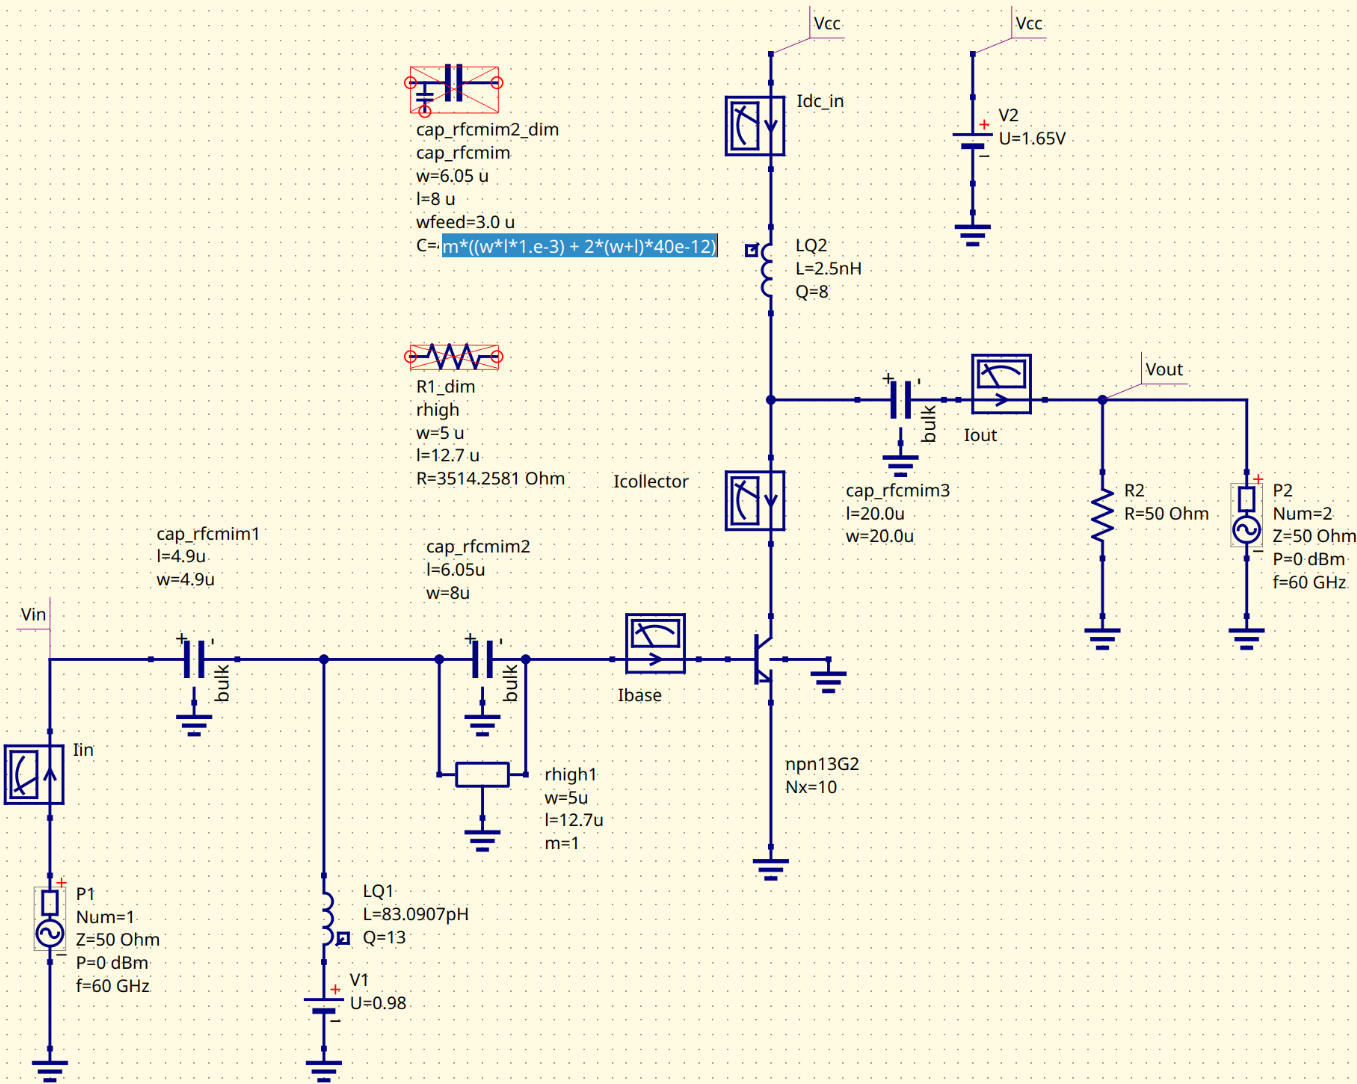

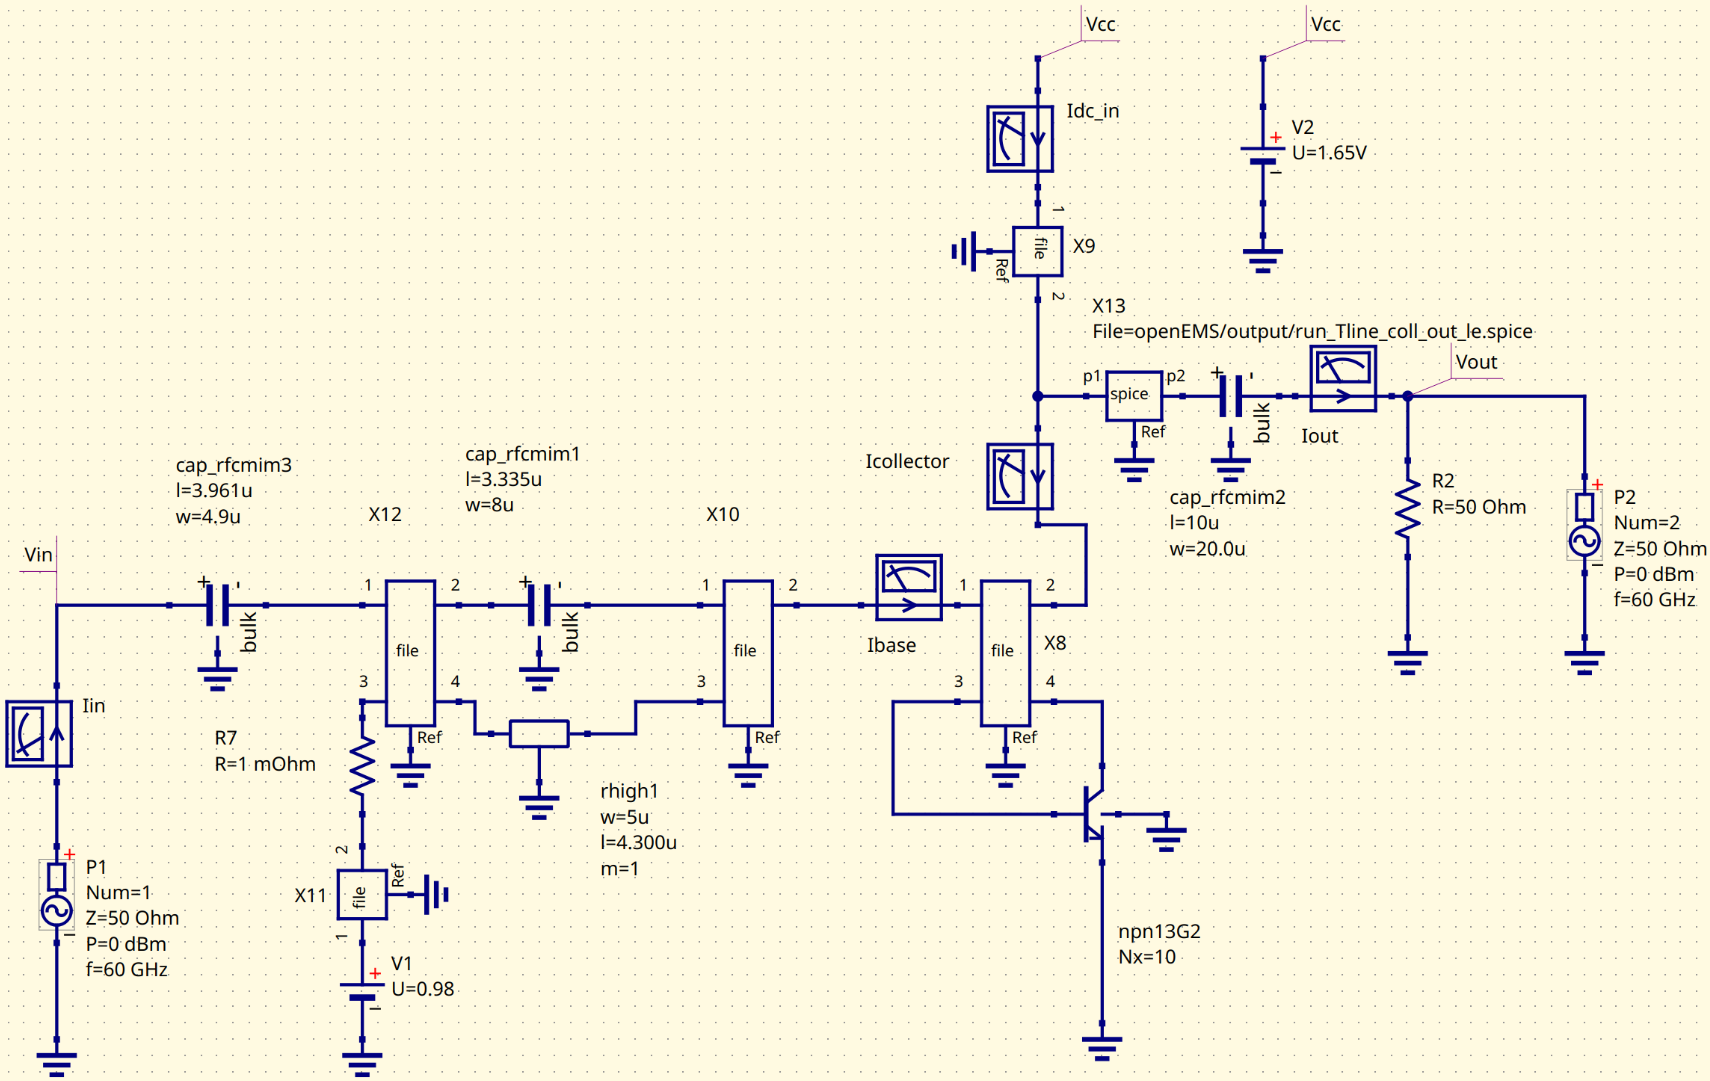

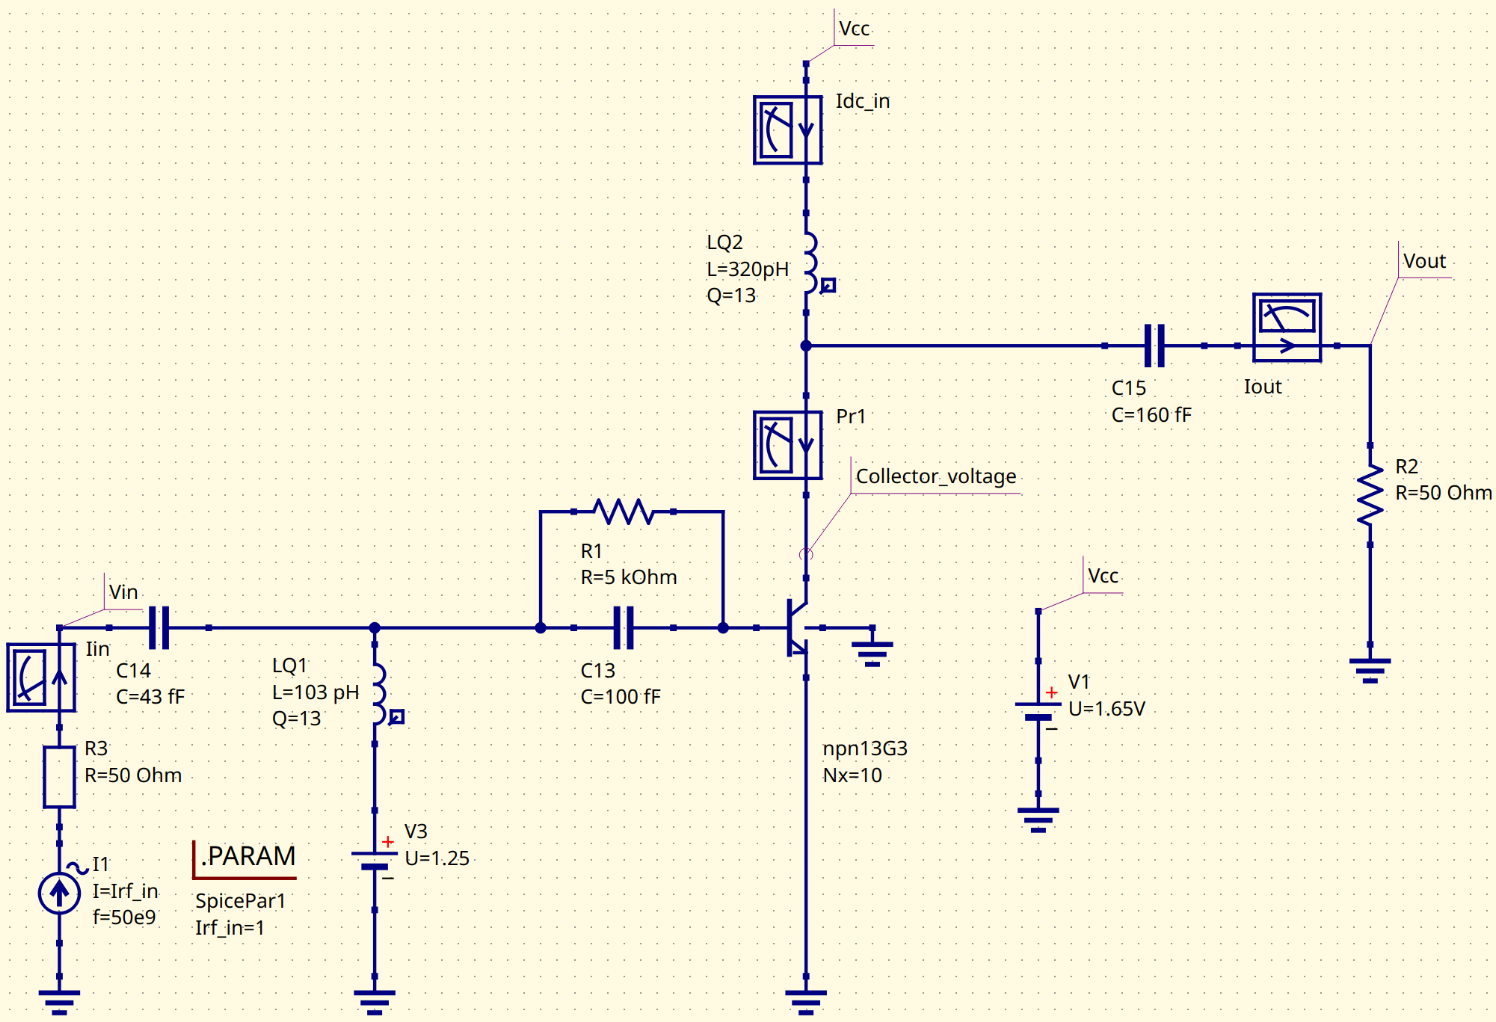

In [ ]:
* === Initial circuit Xyce Script ===
* --- Analysis type definition ---
.HB 50e9

* --- HB solver options ---
.options hbint
+ numfreq=5
+ STARTUPPERIODS=2
+ numtpts=100

* --- Parameter sweep ---
.STEP LIN Irf_in 1e-4 4.5e-3 88e-6

* --- Print output ---
.PRINT HB
+ FORMAT=TECPLOT
+ FILE=/home/matthi/QucsWorkspace/ISSCS_60_GHz_MPA_prj/01_initial_50GHz_MPA_xyce.txt
+ V(Vin) I(VIin) V(Vout) I(VIout) V(VCC) I(VIdc_in)


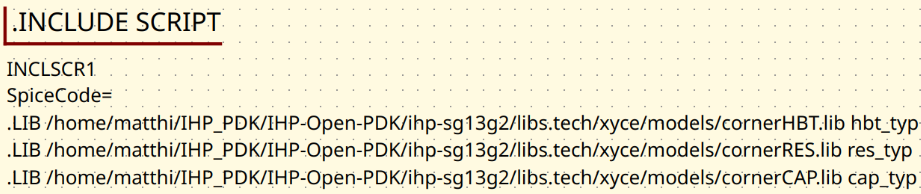

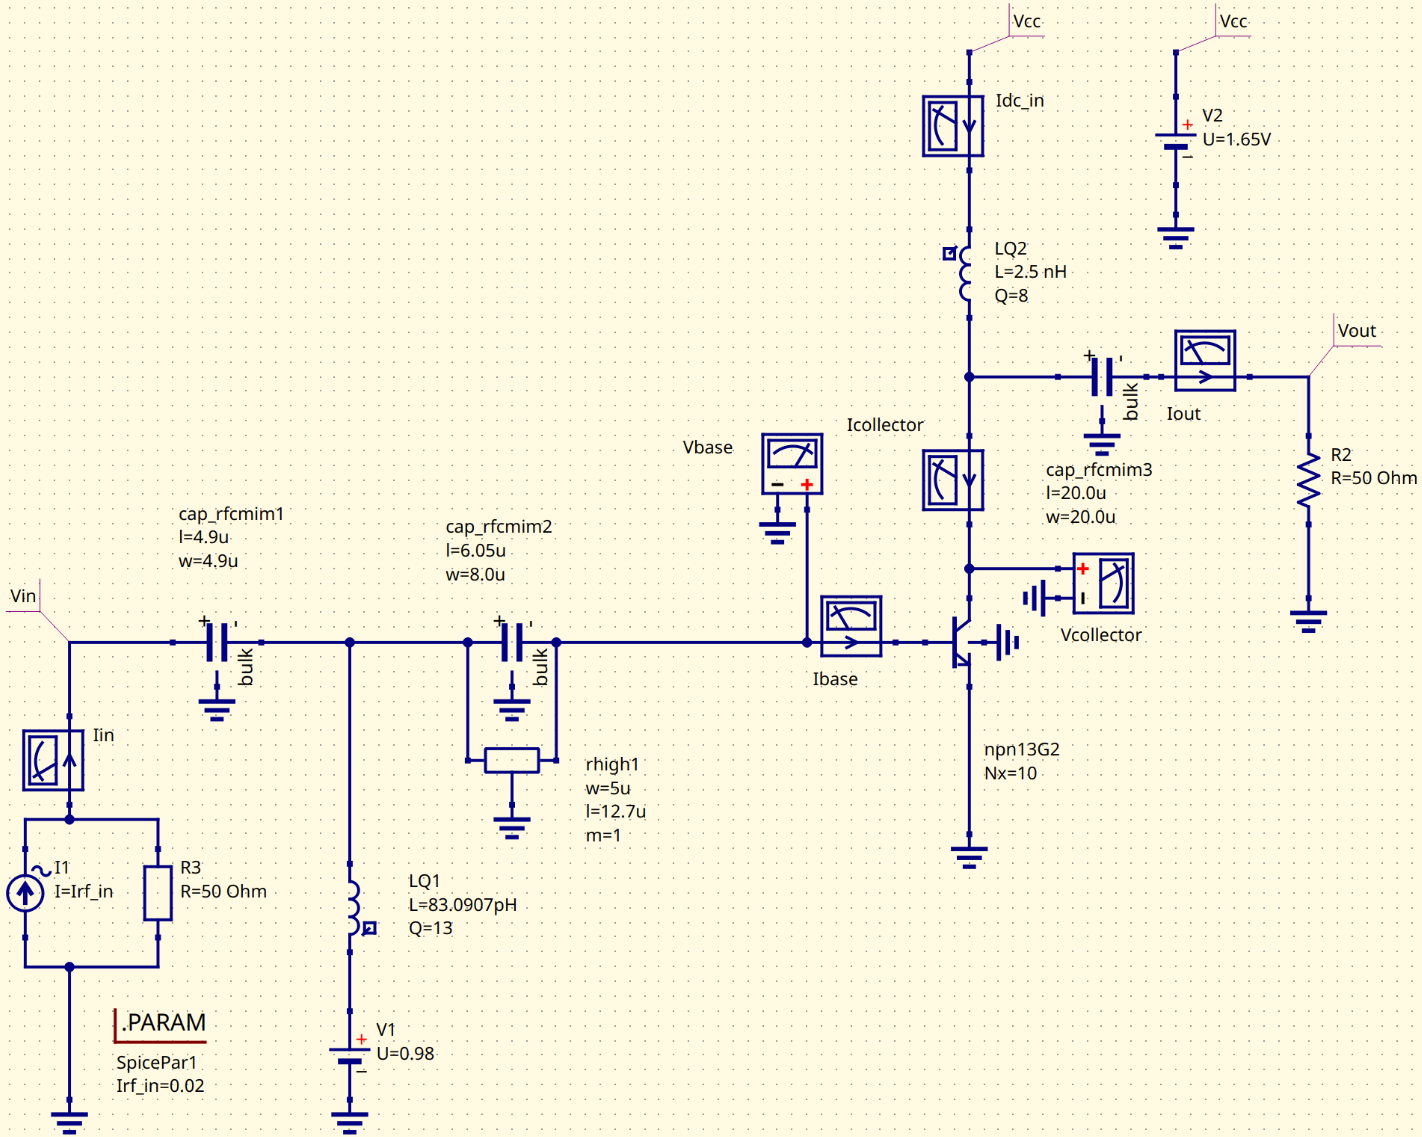

In [ ]:

* === pre-EM circuit Xyce Script ===
* --- Analysis type definition ---
.HB 60e9

* --- HB solver options ---
.options hbint; This is a comment
+ numfreq=10
+ STARTUPPERIODS=2 ; default: 2
+ numtpts=100 ; default: numfreq

* --- DCOP nonlinear solver options ---
.options nonlin
+ abstol=1e-9 ; default: 1e-9
+ reltol=1e-4 ; default: 1e-4

* --- Parameter sweep ---
.STEP LIN Irf_in 0.1e-3 35e-3 3.98e-4

* --- Print output ---
.PRINT HB
+ FORMAT=TECPLOT
+ FILE=/home/matthi/QucsWorkspace/ISSCS_60_GHz_MPA_prj/02_preEM_60GHz_MPA_xyce.txt
+ I(VIin) I(VIbase) I(VIout) V(Vin) V(Vbase) V(Vout) V(Vcc) I(VIdc_in) I(VIcollector) V(Vcollector)


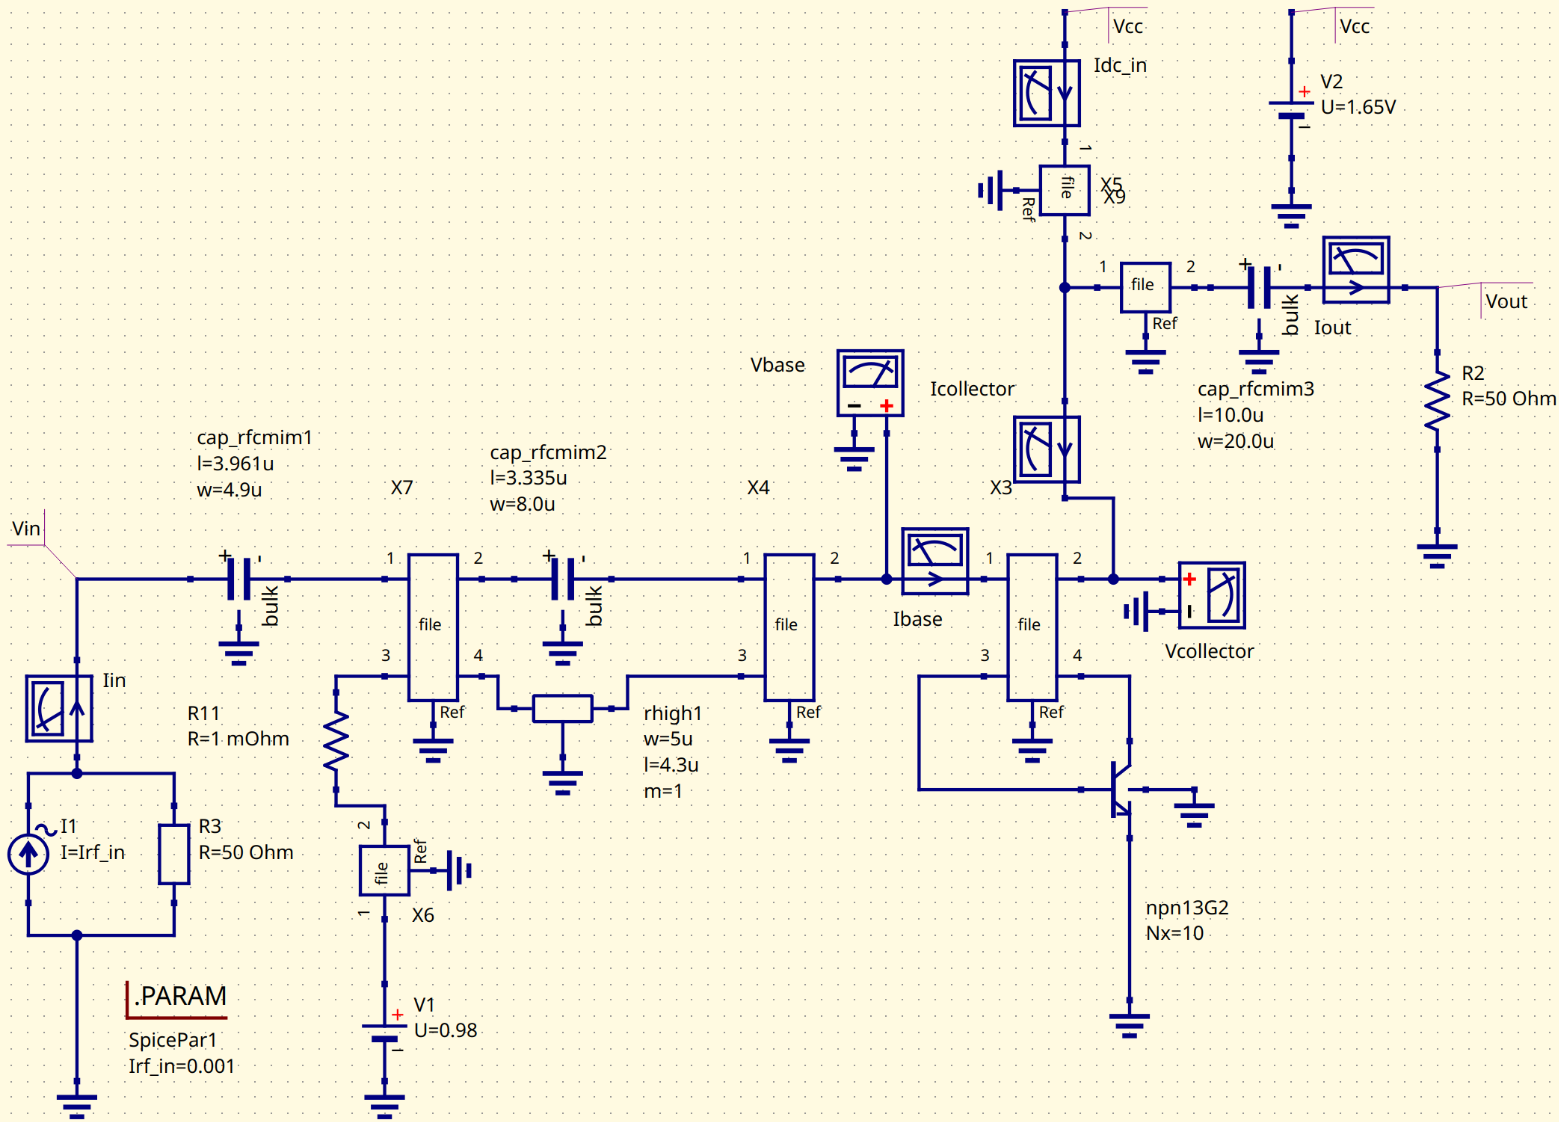

In [ ]:
* === post-EM circuit Xyce Script ===
* --- Analysis type definition ---
.HB 60e9

* --- HB solver options ---
.options hbint;
+ numfreq=10
+ STARTUPPERIODS=2 ; default: 2
+ numtpts=100 ; default: numfreq
+ TAHB=0 ; default: 1

* --- DCOP nonlinear solver options ---
.options nonlin
+ abstol=1e-12 ; default: 1e-12
+ reltol=1e-3 ; default: 1e-3
+ rhstol=1e-6 ; default: 1e-6
+ nox=1 ; default: 1
+ nlstrategy=0 ; default: 0
+ searchmethod=0 ; default: 0

* --- HB nonlinear solver options ---
.options nonlin-hb
+ abstol=1e-9 ; default: 1e-9
+ reltol=1e-4 ; default: 1e-4
+ rhstol=1e-6 ; default: 1e-6

* --- HB linear solver options ---

* --- Parameter sweep ---
.STEP LIN Irf_in 0.1e-3 35e-3 3.98e-4

* --- Print output ---
.PRINT HB
+ FORMAT=TECPLOT
+ FILE=/home/matthi/QucsWorkspace/ISSCS_60_GHz_MPA_prj/03_postEM_60GHz_MPA_xyce.txt
+ I(VIin) I(VIbase) I(VIout) V(Vin) V(Vbase) V(Vout) V(Vcc) I(VIdc_in) I(VIcollector) V(Vcollector)


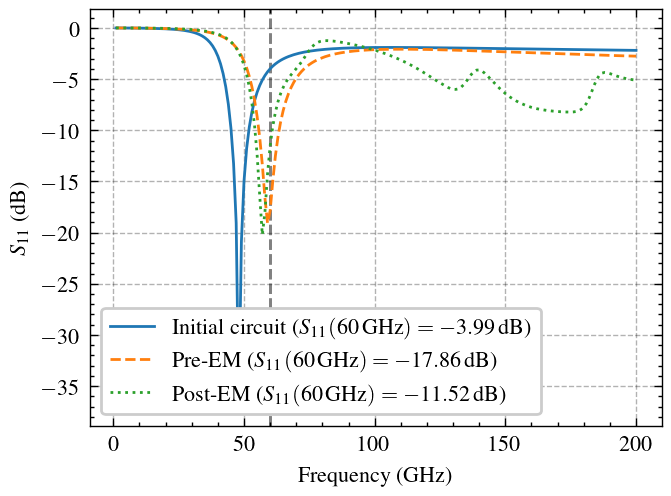

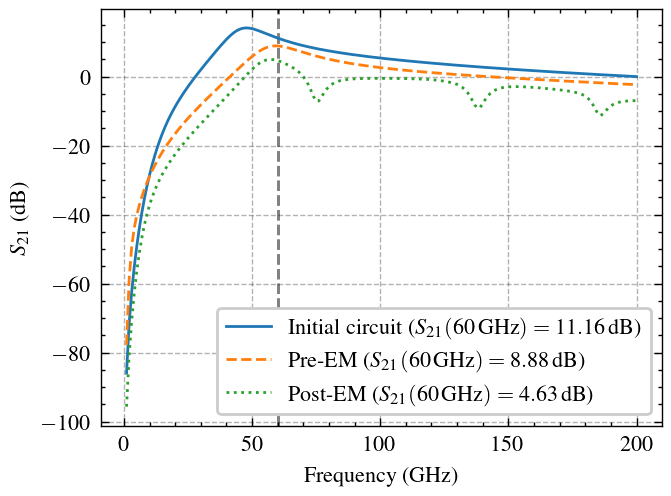

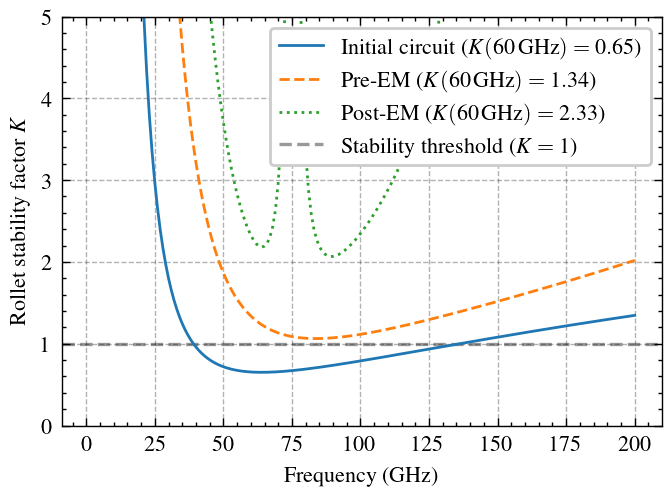

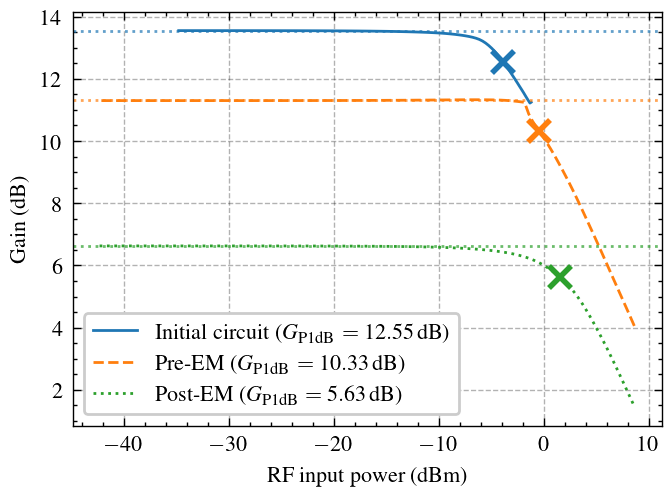